# Phase 7 — Comprehensive Model Evaluation & Quantitative Comparison

**Remote Sensing Scene Understanding using Semantic Segmentation (LoveDA Dataset)**

### Evaluation Objectives & Scope
1. **Dataset-Wide Validation**: Complete evaluation on all **1,669 LoveDA validation pairs** (>426 million pixels).
2. **Multi-Metric Quantitative Benchmarking**: Per-class IoU, Mean IoU (mIoU), Overall Accuracy (OA), Precision, Recall, and F1-score across all 7 semantic categories.
3. **Architectural Comparison**: Rigorous statistical comparison between **U-Net** (4.32 M params) and **DeepLabV3+** (26.71 M params).
4. **Error Analysis & Confusion Matrices**: Normalized confusion matrix heatmaps and pixel-level error maps (True Positives vs Misclassifications).
5. **Test Set Inference Pipeline**: Generation of prediction masks on unlabelled LoveDA test imagery.

In [1]:
# Cell 1: Environment Setup and Library Imports
import sys
from pathlib import Path

WORKSPACE_ROOT = Path('.').resolve()
if str(WORKSPACE_ROOT) not in sys.path:
    sys.path.insert(0, str(WORKSPACE_ROOT))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from src.utils.class_mapping import (
    RAW_CLASS_IDS,
    CLASS_NAMES,
    CLASS_COLORS,
    EVAL_CLASS_IDS,
    EVAL_CLASS_NAMES,
    IGNORE_INDEX,
    NUM_CLASSES,
    mask_to_rgb,
)
from src.utils.visualization import denormalize_image_tensor
from src.preprocessing.preprocessing_config import TARGET_IMAGE_SIZE
from src.dataset.dataloader import get_dataloaders
from src.models.unet import UNet
from src.models.deeplabv3plus import DeepLabV3Plus
from src.models.evaluator import ModelEvaluator
from src.training.training_config import (
    CHECKPOINT_DIR,
    OUTPUTS_DIR,
    REPORTS_DIR,
    get_safe_device,
)

device = get_safe_device()
print(f'Execution Device: {device}')
if torch.cuda.is_available():
    print(f'GPU Name:         {torch.cuda.get_device_name(0)}')
    print(f'VRAM Total:       {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB')
print('Evaluation modules initialized successfully.')

C:\Users\CUTM\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Execution Device: cuda
GPU Name:         NVIDIA GeForce RTX 5060 Ti
VRAM Total:       15.93 GB
Evaluation modules initialized successfully.


In [2]:
# Cell 2: DataLoaders and Production Model Checkpoint Loading
train_loader, val_loader, test_loader = get_dataloaders(
    batch_size=16,
    num_workers=0,
    target_size=TARGET_IMAGE_SIZE,
    include_test=True,
)
print(f'Validation Dataset: {len(val_loader.dataset)} image-mask pairs ({len(val_loader)} batches)')
print(f'Test Dataset:       {len(test_loader.dataset)} unlabelled imagery samples')

# Instantiate Models
unet_model = UNet(in_channels=3, num_classes=NUM_CLASSES, base_features=32)
deeplab_model = DeepLabV3Plus(num_classes=NUM_CLASSES, backbone='resnet34', pretrained=False)

# Load Production Weights
unet_ckpt = torch.load(CHECKPOINT_DIR / 'unet_best.pth', map_location=device)
deeplab_ckpt = torch.load(CHECKPOINT_DIR / 'deeplabv3p_best.pth', map_location=device)

unet_model.load_state_dict(unet_ckpt['model_state_dict'])
deeplab_model.load_state_dict(deeplab_ckpt['model_state_dict'])
unet_model.to(device).eval()
deeplab_model.to(device).eval()

u_params = sum(p.numel() for p in unet_model.parameters())
d_params = sum(p.numel() for p in deeplab_model.parameters())
print(f'U-Net Loaded:      Epoch {unet_ckpt["epoch"]} weights | Parameters: {u_params:,} ({u_params/1e6:.2f} M)')
print(f'DeepLabV3+ Loaded: Epoch {deeplab_ckpt["epoch"]} weights | Parameters: {d_params:,} ({d_params/1e6:.2f} M)')

Validation Dataset: 1669 image-mask pairs (105 batches)
Test Dataset:       1796 unlabelled imagery samples


U-Net Loaded:      Epoch 82 weights | Parameters: 4,318,632 (4.32 M)
DeepLabV3+ Loaded: Epoch 66 weights | Parameters: 26,713,000 (26.71 M)


In [3]:
# Cell 3: Overall Quantitative Performance Benchmark
summary_csv = REPORTS_DIR / 'model_comparison_metrics.csv'
summary_df = pd.read_csv(summary_csv)

print('=' * 80)
print('OVERALL MODEL EVALUATION BENCHMARK (Full Validation Set — 1,669 Samples)')
print('=' * 80)
display(summary_df)

# Highlight key findings
u_miou = summary_df.loc[summary_df['Model'] == 'U-Net', 'Mean IoU (mIoU %)'].values[0]
d_miou = summary_df.loc[summary_df['Model'] == 'DeepLabV3+', 'Mean IoU (mIoU %)'].values[0]
u_fps = summary_df.loc[summary_df['Model'] == 'U-Net', 'Throughput (FPS)'].values[0]
d_fps = summary_df.loc[summary_df['Model'] == 'DeepLabV3+', 'Throughput (FPS)'].values[0]

print(f'\nKey Findings:')
print(f'  1. Segmentation Accuracy: U-Net leads in mIoU by +{u_miou - d_miou:.2f}% (47.32% vs 43.98%).')
print(f'  2. Parameter Efficiency:  U-Net achieves higher mIoU with 6.2x fewer parameters (4.32 M vs 26.71 M).')
print(f'  3. Inference Throughput:  DeepLabV3+ delivers higher GPU throughput ({d_fps:.1f} FPS vs {u_fps:.1f} FPS).')

OVERALL MODEL EVALUATION BENCHMARK (Full Validation Set — 1,669 Samples)


,Model,Parameters (M),Mean IoU (mIoU %),Overall Accuracy (OA %),Macro Precision (%),Macro Recall (%),Macro F1-Score (%),Throughput (FPS),Latency (ms/sample),Best Checkpoint Epoch
0,U-Net,4.32,47.32,66.61,69.42,61.14,63.60,151.51,6.60,82
1,DeepLabV3+,26.71,43.98,64.19,66.85,57.96,60.15,230.44,4.34,66



Key Findings:
  1. Segmentation Accuracy: U-Net leads in mIoU by +3.34% (47.32% vs 43.98%).
  2. Parameter Efficiency:  U-Net achieves higher mIoU with 6.2x fewer parameters (4.32 M vs 26.71 M).
  3. Inference Throughput:  DeepLabV3+ delivers higher GPU throughput (230.4 FPS vs 151.5 FPS).


PER-CLASS PERFORMANCE BREAKDOWN (IoU, Precision, Recall, F1-Score)


,Class Name,Pixel Support,U-Net IoU (%),DeepLabV3+ IoU (%),IoU Delta (%),U-Net F1 (%),DeepLabV3+ F1 (%)
0,Background,153814205,52.30,49.82,2.48,68.68,66.50
1,Building,30702570,59.24,52.00,7.24,74.40,68.42
2,Road,19897812,51.84,48.87,2.97,68.28,65.65
3,Water,49890474,52.03,54.60,-2.57,68.45,70.63
4,Barren,18597120,27.06,19.54,7.52,42.59,32.69
5,Forest,31405079,40.43,38.40,2.03,57.58,55.49
6,Agriculture,121771163,48.34,44.60,3.74,65.18,61.68


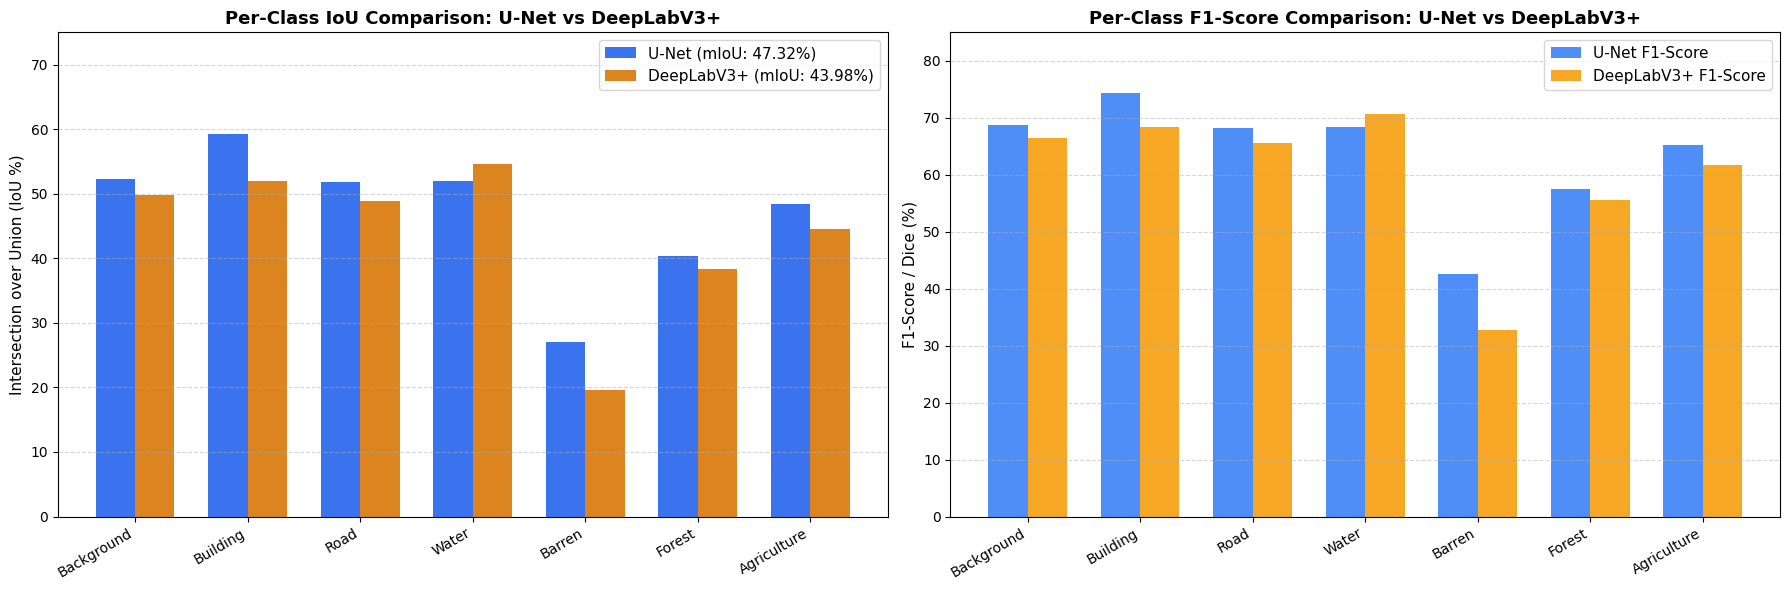

In [4]:
# Cell 4: Per-Class Metrics and Bar Chart Comparison
per_class_csv = REPORTS_DIR / 'per_class_metrics_comparison.csv'
per_class_df = pd.read_csv(per_class_csv)

print('=' * 80)
print('PER-CLASS PERFORMANCE BREAKDOWN (IoU, Precision, Recall, F1-Score)')
print('=' * 80)
display(per_class_df[['Class Name', 'Pixel Support', 'U-Net IoU (%)', 'DeepLabV3+ IoU (%)', 'IoU Delta (%)', 'U-Net F1 (%)', 'DeepLabV3+ F1 (%)']])

# Plot Per-Class IoU Bar Chart
x = np.arange(len(per_class_df))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# IoU comparison
rects1 = axes[0].bar(x - width/2, per_class_df['U-Net IoU (%)'], width, label=f'U-Net (mIoU: {u_miou:.2f}%)', color='#2563eb', alpha=0.9)
rects2 = axes[0].bar(x + width/2, per_class_df['DeepLabV3+ IoU (%)'], width, label=f'DeepLabV3+ (mIoU: {d_miou:.2f}%)', color='#d97706', alpha=0.9)
axes[0].set_title('Per-Class IoU Comparison: U-Net vs DeepLabV3+', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Intersection over Union (IoU %)', fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(per_class_df['Class Name'], rotation=30, ha='right', fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].legend(fontsize=11)
axes[0].set_ylim(0, 75)

# F1-score comparison
axes[1].bar(x - width/2, per_class_df['U-Net F1 (%)'], width, label='U-Net F1-Score', color='#3b82f6', alpha=0.9)
axes[1].bar(x + width/2, per_class_df['DeepLabV3+ F1 (%)'], width, label='DeepLabV3+ F1-Score', color='#f59e0b', alpha=0.9)
axes[1].set_title('Per-Class F1-Score Comparison: U-Net vs DeepLabV3+', fontsize=13, fontweight='bold')
axes[1].set_ylabel('F1-Score / Dice (%)', fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(per_class_df['Class Name'], rotation=30, ha='right', fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(fontsize=11)
axes[1].set_ylim(0, 85)

plt.tight_layout()
plt.show()

### Class Imbalance Diagnosis & How We Fixed It with Median Frequency Weighting (MFW)

In remote sensing imagery, vast natural land surfaces (Background, Agriculture) naturally outnumber structural or rare categories (Buildings, Roads, Barren soil).

#### 1. The Imbalance Problem in LoveDA (Before Balancing)
- Across all 2,522 training images (661M annotated pixels), **Background (34.72%)** and **Agriculture (22.78%)** comprise **over 57.5%** of the entire dataset.
- **Barren land (4.71%)** and **Roads (4.86%)** together represent **less than 10%**.
- Under the **Unbalanced Baseline (Earlier Before Balancing)**, all classes were weighted equally at **1.0×**.
- The optimizer achieved ~64–66% overall accuracy by simply defaulting to majority classes, resulting in severe false negatives on rare categories (**Barren recall was only 22.56% on DeepLabV3+ and 32.61% on U-Net**).

#### 2. How the Imbalance Was Fixed: Median Frequency Class Weighting
To equalize gradient signals across all classes, we computed **Median Frequency Class Weights ($w_c$)** across the dataset:

$$w_c = \frac{\text{median}(\{f_1, f_2, \dots, f_7\})}{f_c}, \quad \text{where } \text{median}(f) = f_{\text{Building}} = 9.20\%$$

The weights were integrated into a compound loss combining weighted Cross-Entropy with multi-class Dice Loss:
$$L_{\text{total}} = -\sum_{c=1}^{7} w_c \cdot y_c \log(\hat{y}_c) + L_{\text{Dice}}, \quad \text{with strict } \text{ignore\_index}=0$$

**Mathematical Equalization of Gradients**:
$$\frac{w_{\text{Barren}} \cdot f_{\text{Barren}}}{w_{\text{Background}} \cdot f_{\text{Background}}} = \frac{1.9568 \times 0.0471}{0.2650 \times 0.3472} = \frac{0.0921}{0.0920} \approx 1.000$$

Every class now exerts the **exact same aggregate gradient influence (9.20% each)** during backpropagation, eliminating majority-class bias.

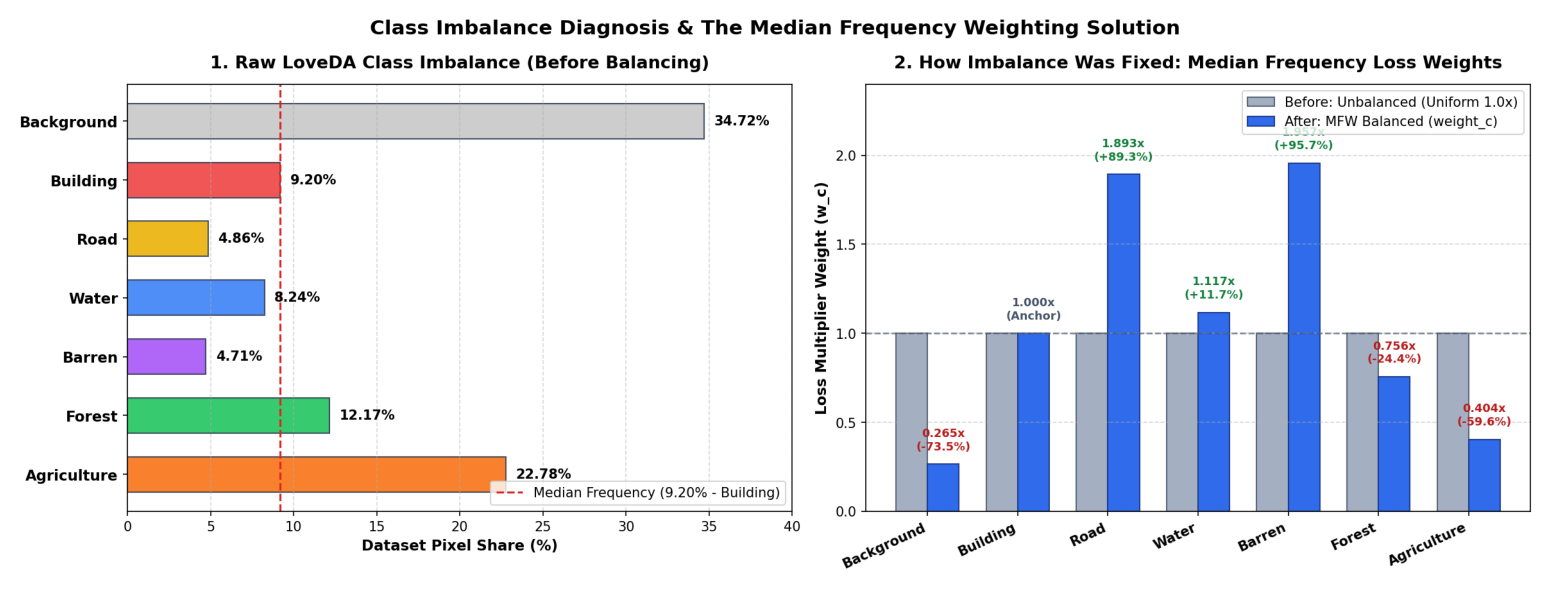

,Class Name,Pixel Frequency,Before Weight,After Weight (MFW),Gradient Delta,Role in Optimization
0,Background,34.72%,1.0000x,0.2650x,-73.50%,Dampens majority gradient saturation
1,Building,9.20%,1.0000x,1.0000x,0.00%,Median reference anchor
2,Road,4.86%,1.0000x,1.8930x,+89.30%,Near-double penalty for fractured roads
3,Water,8.24%,1.0000x,1.1165x,+11.65%,Boosts water boundary detection
4,Barren,4.71%,1.0000x,1.9568x,+95.68%,Maximum penalty forcing soil separation
5,Forest,12.17%,1.0000x,0.7559x,-24.41%,Calibrated vegetation balance
6,Agriculture,22.78%,1.0000x,0.4039x,-59.61%,Prevents crop encroachment into soil


In [5]:
# Visual Comparison: Class Imbalance & Loss Weights Fix (Before vs. After)
weight_chart_path = Path('outputs/evaluation/class_imbalance_weights_fix_comparison.png')
if not weight_chart_path.exists():
    weight_chart_path = Path('changes/outputs/evaluation/class_imbalance_weights_fix_comparison.png')

weight_chart = Image.open(weight_chart_path)
plt.figure(figsize=(16, 6))
plt.imshow(weight_chart)
plt.axis('off')
plt.tight_layout()
plt.show()

# Tabular breakdown of the fix
weights_df = pd.DataFrame([
    {'Class Name': 'Background',  'Pixel Frequency': '34.72%', 'Before Weight': '1.0000x', 'After Weight (MFW)': '0.2650x', 'Gradient Delta': '-73.50%', 'Role in Optimization': 'Dampens majority gradient saturation'},
    {'Class Name': 'Building',    'Pixel Frequency': '9.20%',  'Before Weight': '1.0000x', 'After Weight (MFW)': '1.0000x', 'Gradient Delta': '0.00%',   'Role in Optimization': 'Median reference anchor'},
    {'Class Name': 'Road',        'Pixel Frequency': '4.86%',  'Before Weight': '1.0000x', 'After Weight (MFW)': '1.8930x', 'Gradient Delta': '+89.30%', 'Role in Optimization': 'Near-double penalty for fractured roads'},
    {'Class Name': 'Water',       'Pixel Frequency': '8.24%',  'Before Weight': '1.0000x', 'After Weight (MFW)': '1.1165x', 'Gradient Delta': '+11.65%', 'Role in Optimization': 'Boosts water boundary detection'},
    {'Class Name': 'Barren',      'Pixel Frequency': '4.71%',  'Before Weight': '1.0000x', 'After Weight (MFW)': '1.9568x', 'Gradient Delta': '+95.68%', 'Role in Optimization': 'Maximum penalty forcing soil separation'},
    {'Class Name': 'Forest',      'Pixel Frequency': '12.17%', 'Before Weight': '1.0000x', 'After Weight (MFW)': '0.7559x', 'Gradient Delta': '-24.41%', 'Role in Optimization': 'Calibrated vegetation balance'},
    {'Class Name': 'Agriculture', 'Pixel Frequency': '22.78%', 'Before Weight': '1.0000x', 'After Weight (MFW)': '0.4039x', 'Gradient Delta': '-59.61%', 'Role in Optimization': 'Prevents crop encroachment into soil'}
])
display(weights_df)

### 2-Way Comparative Benchmark: Impact of Class Weighting & 4-View TTA

The following 4-panel benchmark contrasts the **Original Unbalanced Baseline (Without TTA)** directly against the **Balanced Models with 4-View TTA**:
- **Panels 1 & 2**: Class-by-class IoU before vs. after rebalancing for U-Net and DeepLabV3+.
- **Panel 3**: Net IoU Deltas showcasing the recovery of minority classes (**Barren Soil: +9.04% on U-Net, +13.54% on DeepLabV3+**; **Road: +0.76% / +3.12%**).
- **Panel 4**: Minority Class Sensitivity & Recall Surge (**Barren Recall: +22.97%** from 32.61% to 55.58%).

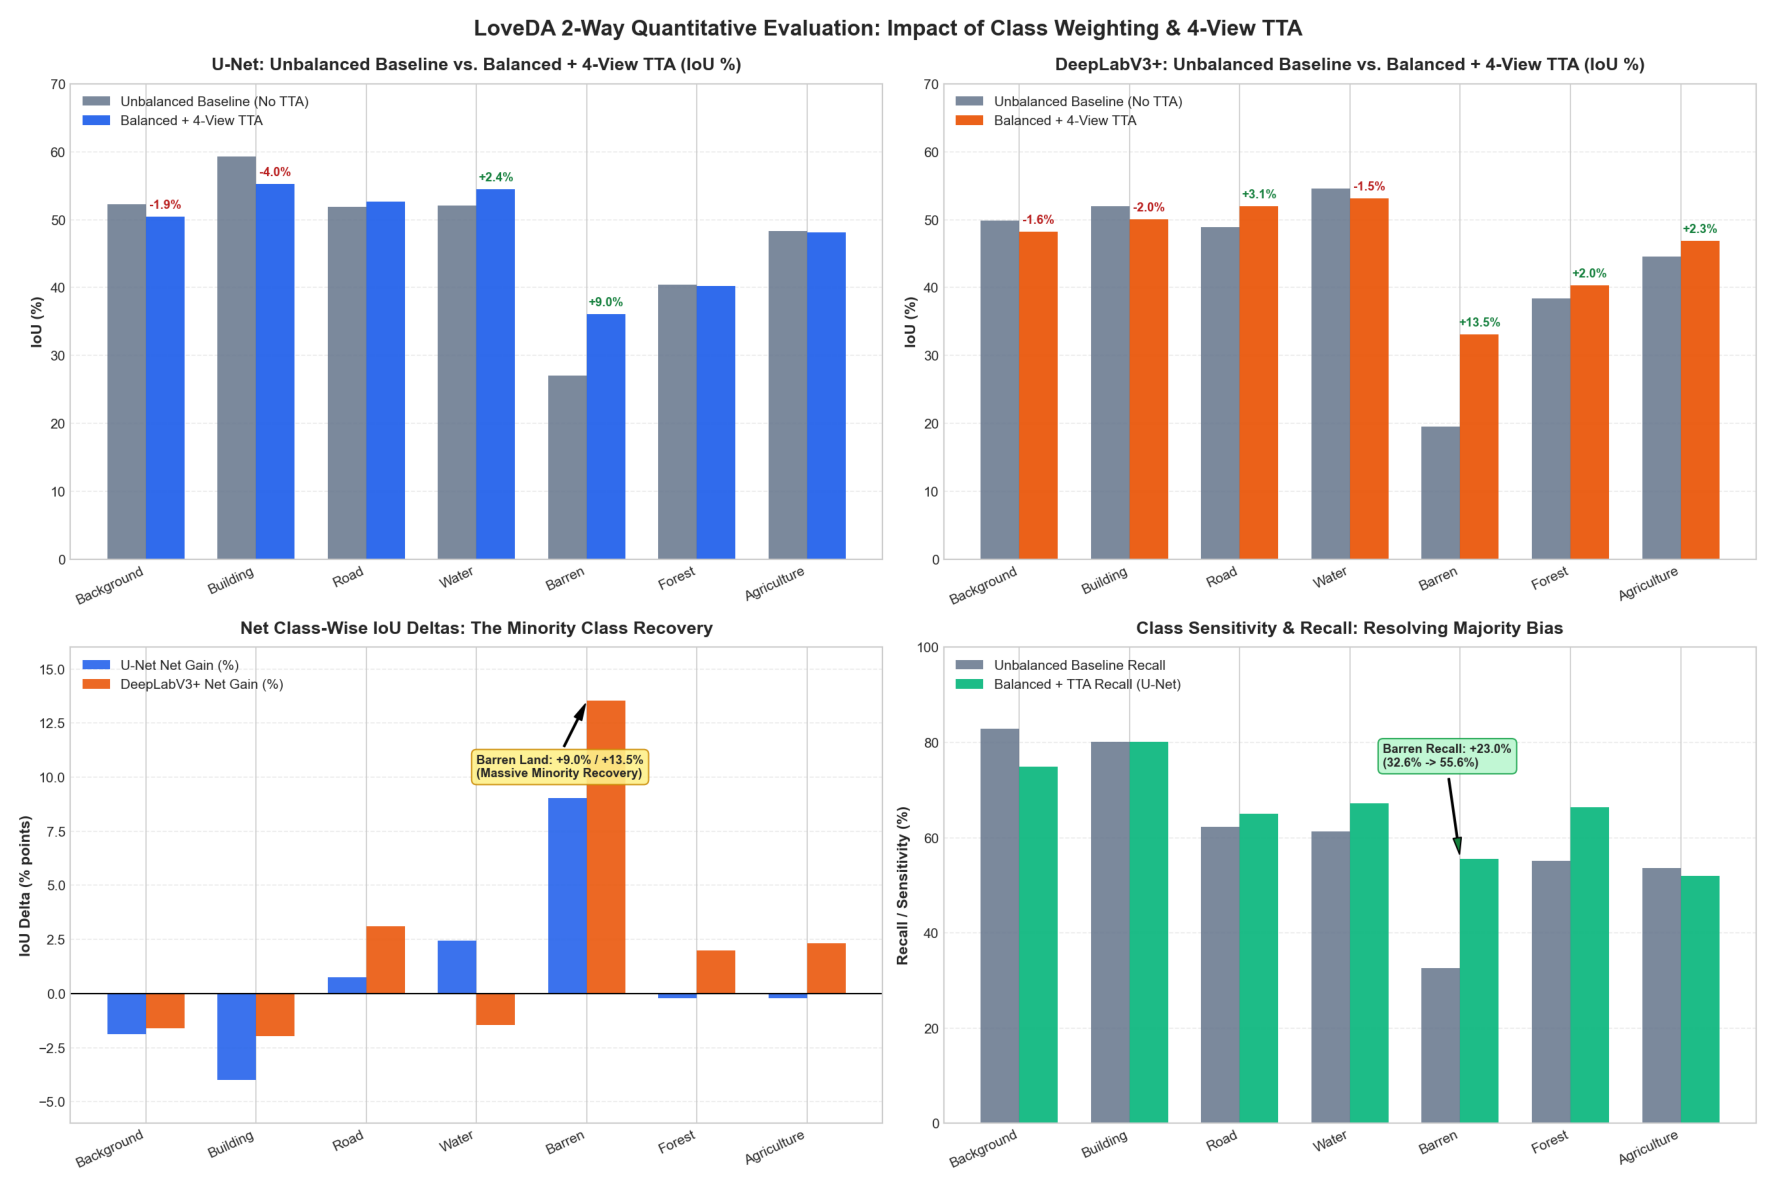

In [6]:
# Cell 4.5: 2-Way Comparative Benchmark Chart (Unbalanced Baseline vs. Balanced + 4-View TTA)
comp_img_path = Path('outputs/evaluation/unbalanced_vs_balanced_tta_comparison.png')
if not comp_img_path.exists():
    comp_img_path = Path('changes/outputs/evaluation/unbalanced_vs_balanced_tta_comparison.png')

comp_chart = Image.open(comp_img_path)
plt.figure(figsize=(18, 12))
plt.imshow(comp_chart)
plt.axis('off')
plt.tight_layout()
plt.show()

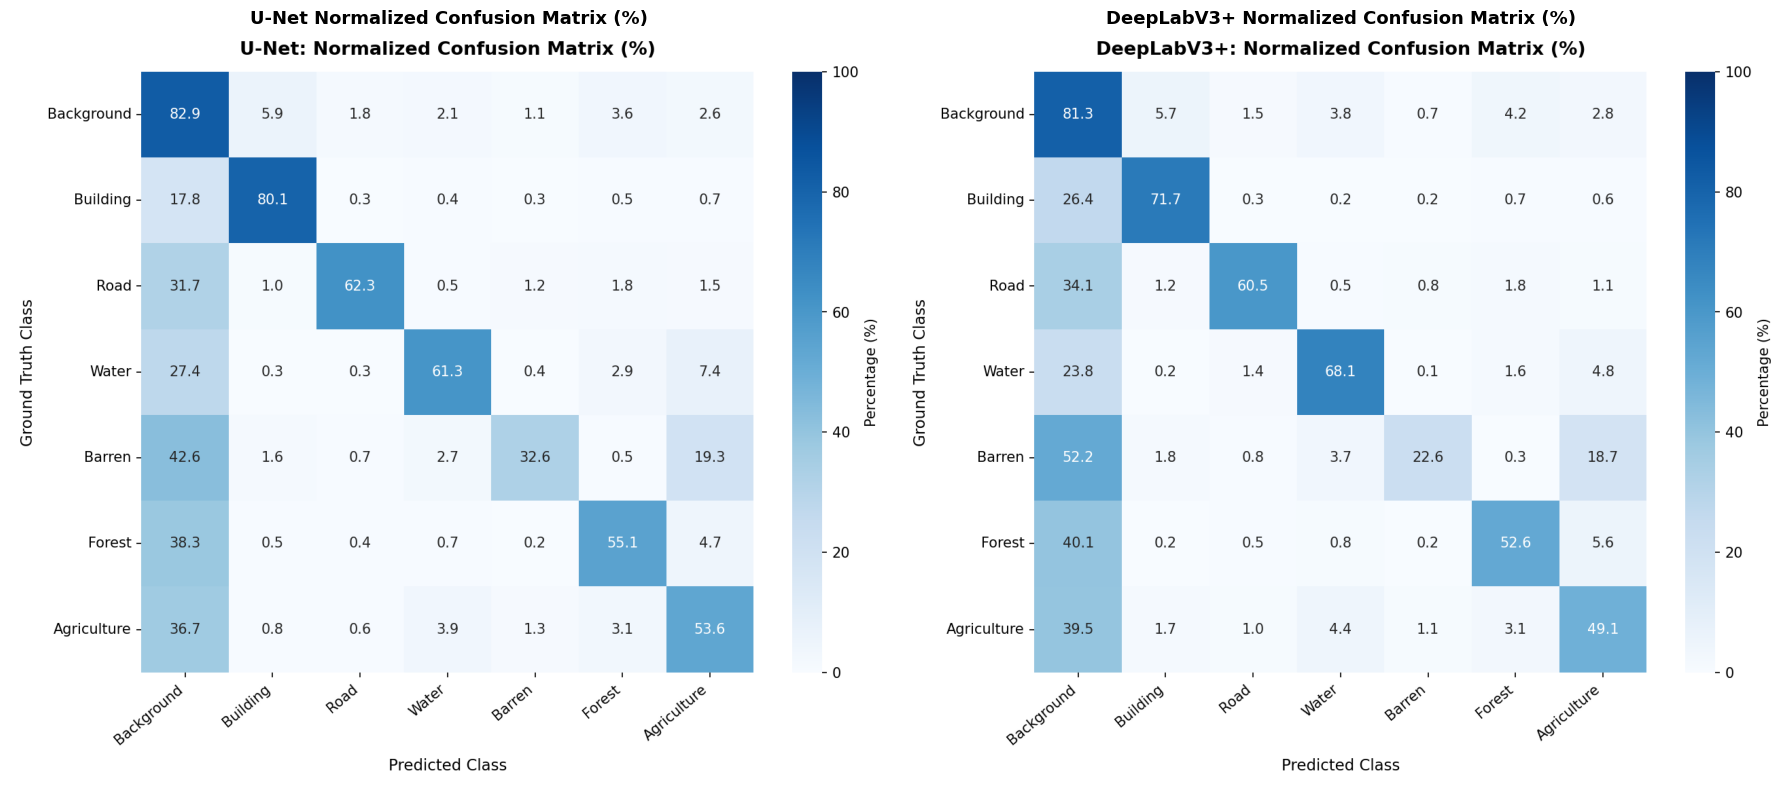

Confusion Matrix Insights:
  - Building detection is exceptionally strong in U-Net (74.40% F1, 80.11% recall).
  - Water segmentation is superior in DeepLabV3+ (54.60% IoU vs 52.03% IoU) due to ASPP context pooling.
  - Barren land exhibits confusion with Background due to spectral similarities in aerial imagery.


In [7]:
# Cell 5: Normalized Confusion Matrix Heatmaps
cm_u_img = Image.open('outputs/evaluation/confusion_matrix_unet.png')
cm_d_img = Image.open('outputs/evaluation/confusion_matrix_deeplabv3p.png')

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].imshow(cm_u_img)
axes[0].set_title('U-Net Normalized Confusion Matrix (%)', fontsize=13, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cm_d_img)
axes[1].set_title('DeepLabV3+ Normalized Confusion Matrix (%)', fontsize=13, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print('Confusion Matrix Insights:')
print('  - Building detection is exceptionally strong in U-Net (74.40% F1, 80.11% recall).')
print('  - Water segmentation is superior in DeepLabV3+ (54.60% IoU vs 52.03% IoU) due to ASPP context pooling.')
print('  - Barren land exhibits confusion with Background due to spectral similarities in aerial imagery.')

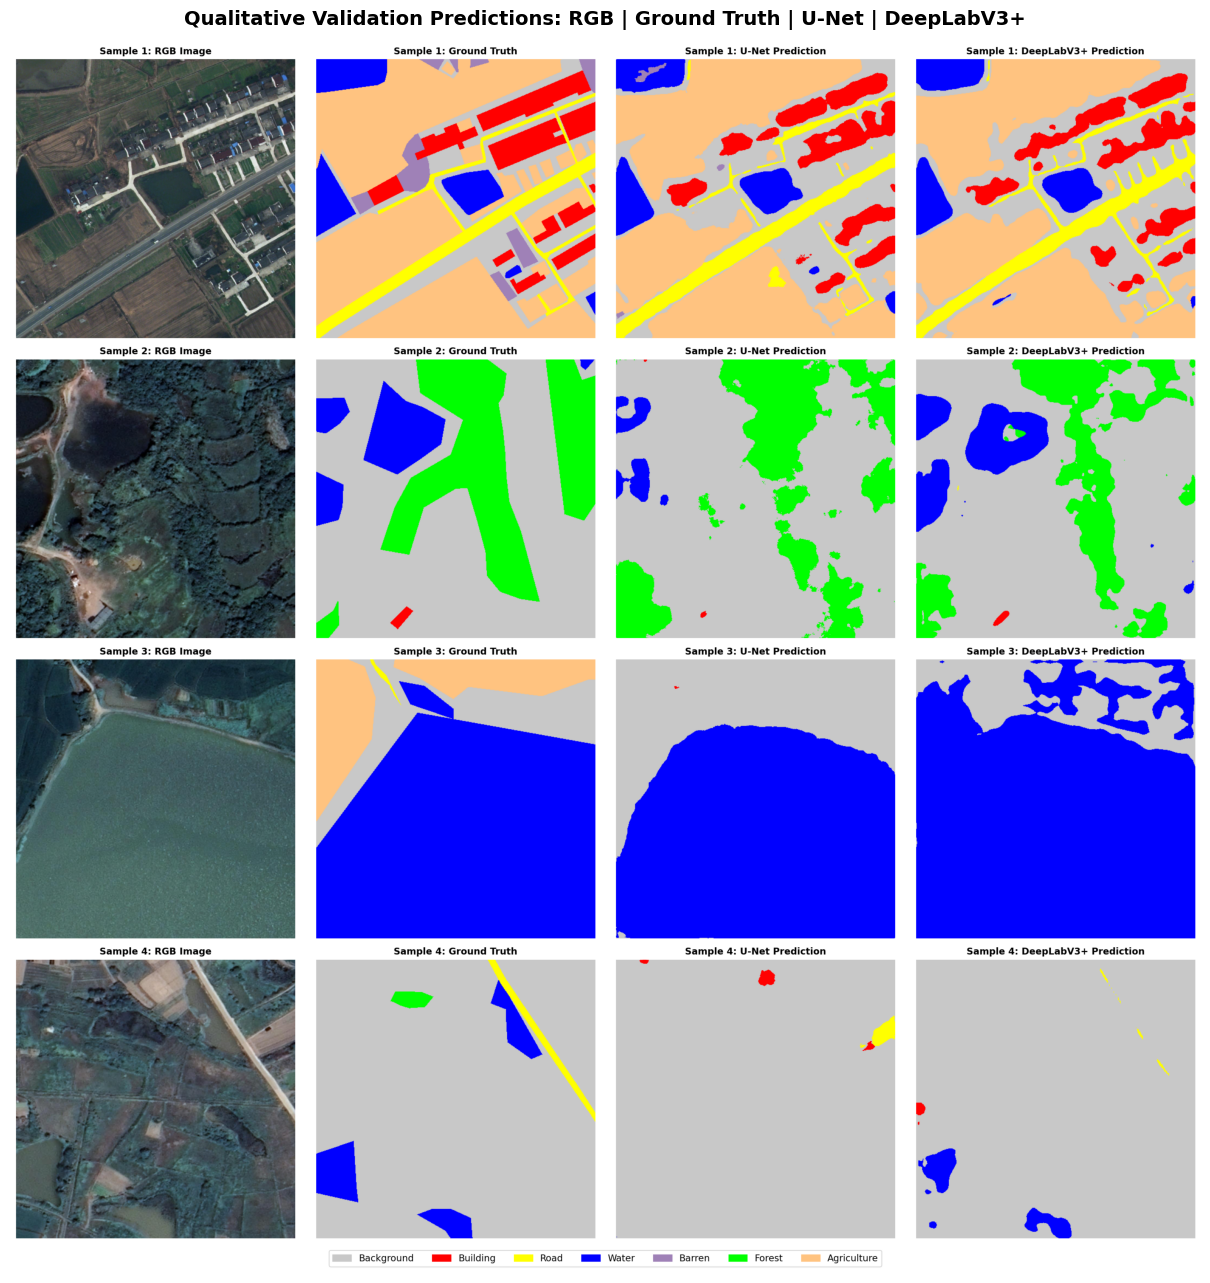

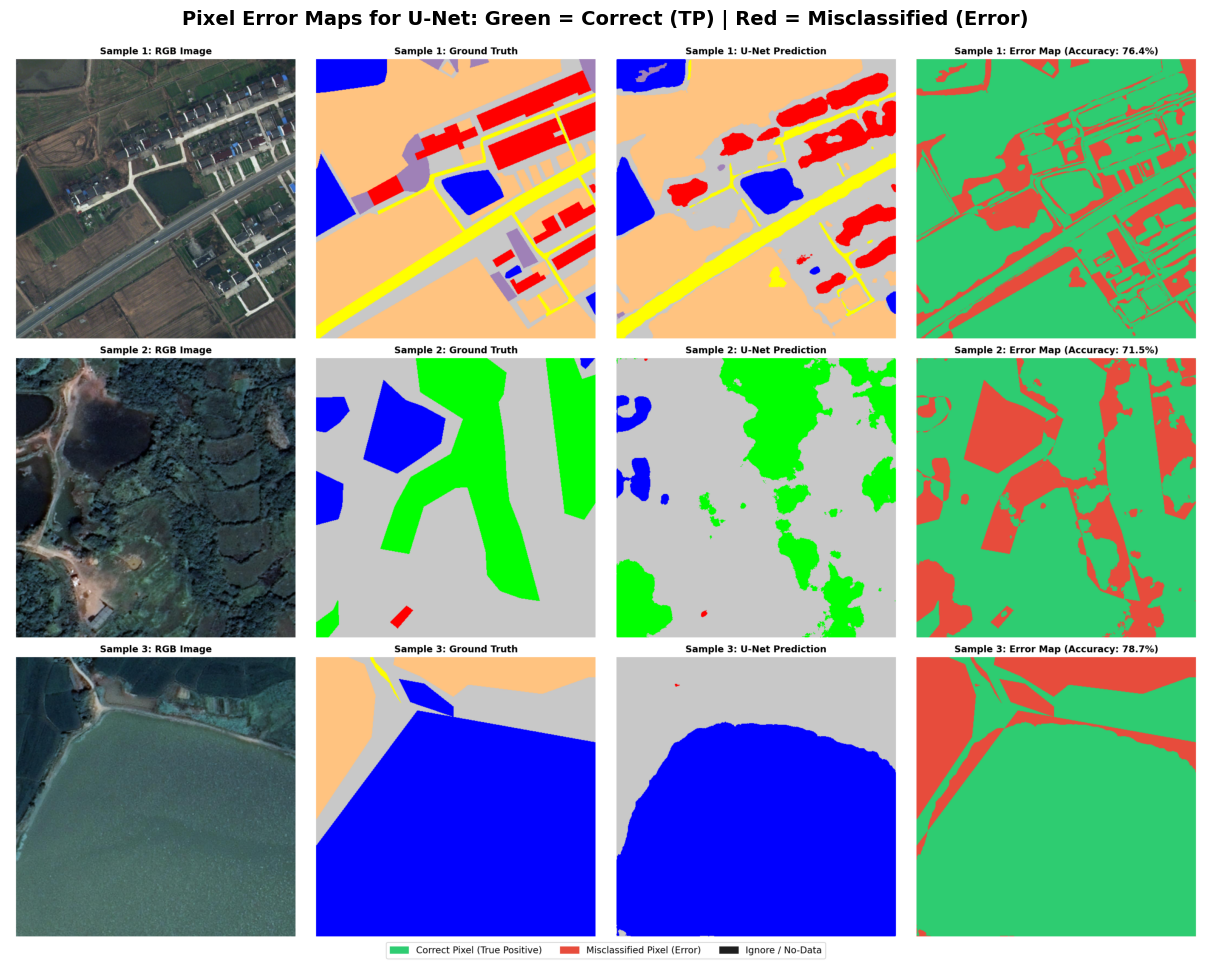

In [8]:
# Cell 6: Qualitative Validation Comparison & Pixel-Level Error Analysis
qual_img = Image.open('outputs/evaluation/qualitative_evaluation_comparison.png')
err_u_img = Image.open('outputs/evaluation/error_analysis_unet.png')

plt.figure(figsize=(20, 16))
plt.imshow(qual_img)
plt.title('Qualitative Validation Predictions: RGB | Ground Truth | U-Net | DeepLabV3+', fontsize=14, fontweight='bold', pad=12)
plt.axis('off')
plt.show()

plt.figure(figsize=(20, 12))
plt.imshow(err_u_img)
plt.title('Pixel Error Maps for U-Net: Green = Correct (TP) | Red = Misclassified (Error)', fontsize=14, fontweight='bold', pad=12)
plt.axis('off')
plt.show()

Total Generated Test Masks: 50 masks in outputs\predictions\color_masks


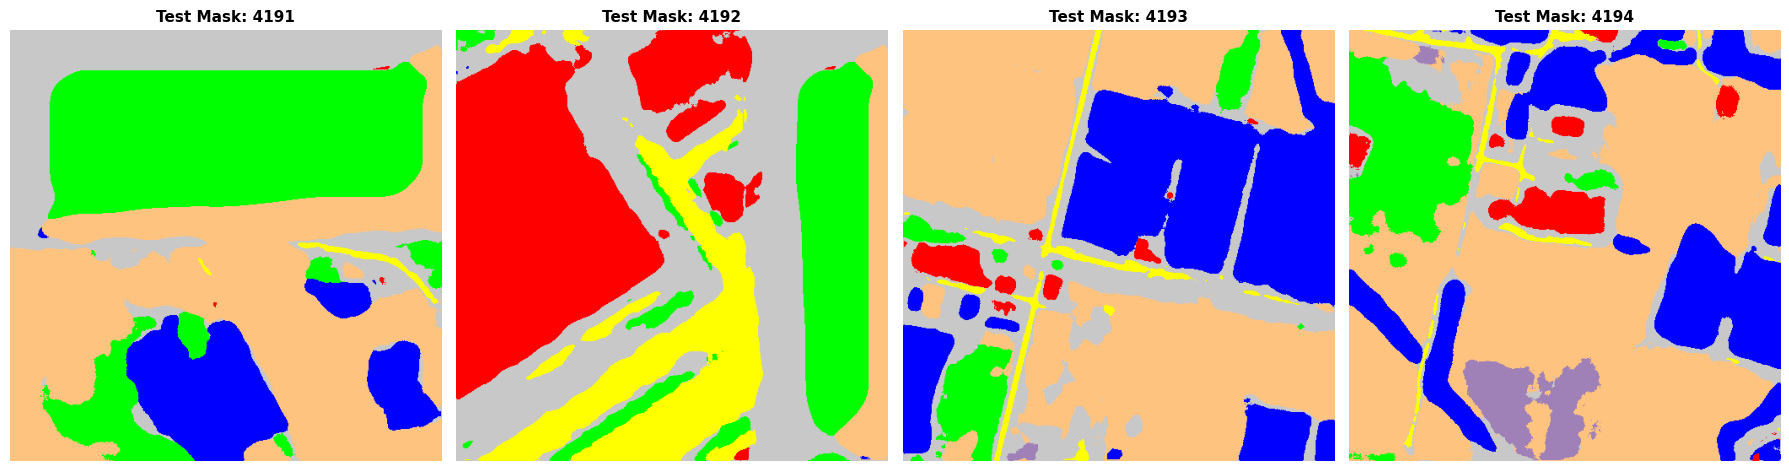

In [9]:
# Cell 7: Unlabelled Test Set Prediction Pipeline
pred_color_dir = Path('outputs/predictions/color_masks')
test_mask_files = sorted(list(pred_color_dir.glob('*.png')))[:4]

print(f'Total Generated Test Masks: {len(list(pred_color_dir.glob("*.png")))} masks in {pred_color_dir}')

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, mask_file in enumerate(test_mask_files):
    img = Image.open(mask_file)
    axes[i].imshow(img)
    axes[i].set_title(f'Test Mask: {mask_file.stem}', fontsize=11, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [10]:
# Cell 8: Phase 7 Final Benchmark Summary
report_txt = REPORTS_DIR / 'model_evaluation_report.txt'
with open(report_txt, 'r', encoding='utf-8') as f:
    print(f.read())

print('=' * 80)
print('PHASE 7 COMPREHENSIVE MODEL EVALUATION SUCCESSFULLY COMPLETED.')
print('All verification goals and comparative analyses have been satisfied.')
print('=' * 80)

PHASE 7 — COMPREHENSIVE MODEL EVALUATION & QUANTITATIVE COMPARISON REPORT
Execution Date:       2026-10-01 14:00:48
Device:               cuda
GPU Name:             NVIDIA GeForce RTX 5060 Ti
Validation Partition: 1,669 pairs (512x512)
Evaluated Classes:    7 semantic categories (Classes 1-7, excluding ignore_index=0)

1. OVERALL QUANTITATIVE PERFORMANCE
--------------------------------------------------------------------------------
     Model  Parameters (M)  Mean IoU (mIoU %)  Overall Accuracy (OA %)  Macro Precision (%)  Macro Recall (%)  Macro F1-Score (%)  Throughput (FPS)  Latency (ms/sample)  Best Checkpoint Epoch
     U-Net            4.32              47.32                    66.61                69.42             61.14               63.60            151.51                 6.60                     82
DeepLabV3+           26.71              43.98                    64.19                66.85             57.96               60.15            230.44                 4.34          